# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

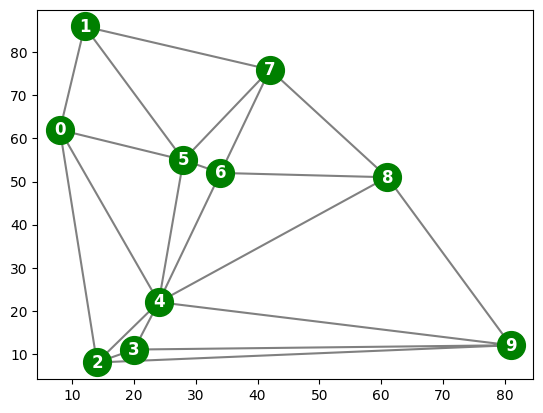

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [3]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [4]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [5]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


In [6]:
# 1. Phép gán rỗng
print("Test 1 (Rỗng):", complete({}, csp), consistent({}, csp)) 

# 2. Phép gán một phần hợp lệ (Chỉ tô màu vài đỉnh, không vi phạm)
partial_assign = {'0': 'red', '1': 'blue'}
print("Test 2 (Một phần):", complete(partial_assign, csp), consistent(partial_assign, csp))

# 3. Phép gán vi phạm ràng buộc (2 đỉnh kề nhau bị tô cùng màu)
# (Kiểm tra xem '0' và '1' có kề nhau trong đồ thị không, nếu có thì sẽ báo False)
conflict_assign = {'0': 'red', '1': 'red'}
print("Test 3 (Xung đột):", complete(conflict_assign, csp), consistent(conflict_assign, csp))

Test 1 (Rỗng): False True
Test 2 (Một phần): False True
Test 3 (Xung đột): False False


## Implement Simple Backtracking Search

In [7]:
def select_unassigned_var(assignment, csp):
    if complete(assignment, csp): 
        return None
    
    # Lấy danh sách các đỉnh chưa được tô màu
    unassigned_vars = [v for v in csp['variables'] if v not in assignment.keys()]
    
    # Hàm đếm số màu hợp lệ còn lại của một đỉnh
    def count_legal_values(var):
        legal_count = 0
        for color in csp['domains'][var]:
            test_assignment = assignment.copy()
            test_assignment[var] = color
            if consistent(test_assignment, csp):
                legal_count += 1
        return legal_count

    # Trả về đỉnh có số màu hợp lệ còn lại ít nhất
    return min(unassigned_vars, key=count_legal_values)

In [8]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0
    
    assignment = backtrack({}, csp)
    
    print(f"Checked nodes: {COUNT}")
    
    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT
    
    COUNT += 1
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    # TODO: implement value ordering. Use the least-constraining-value heuristic. 
    # for val in order_domain(assignment, var, csp)
    for val in csp['domains'][var]:
        assignment[var] = val
        
        if VERBOSE: print(f"Checking: {assignment}")
        
        if consistent(assignment, csp):
            
            #TODO: add inference for early failing (forward checking, )
            # if inference_fails(assignment, csp): return(None)
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)
                
        del assignment[var]
        
    if VERBOSE: print(f"Backtracking")
    return(None) 

## Run Backtracking Search on the Random Problem

In [9]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
CPU times: total: 15.6 ms
Wall time: 1.88 ms


{'0': 'red',
 '1': 'blue',
 '5': 'green',
 '4': 'blue',
 '2': 'green',
 '3': 'red',
 '9': 'orange',
 '6': 'red',
 '7': 'orange',
 '8': 'green'}

Plot the resulting coloring

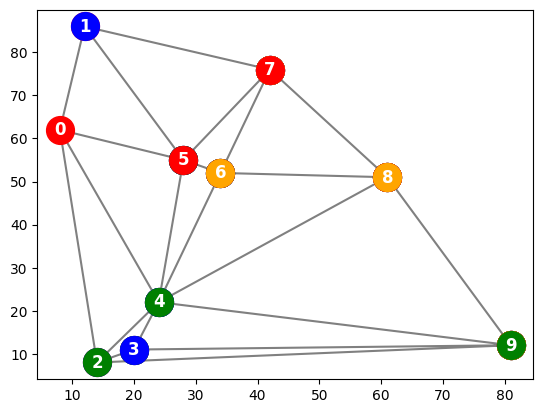

In [10]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

In [11]:
def forward_check(assignment, var, color, csp, local_domains):
    """
    Loại bỏ màu vừa tô khỏi miền giá trị của các đỉnh láng giềng chưa gán.
    Nếu có đỉnh láng giềng nào cạn kiệt màu (không còn màu nào để tô) -> Trả về False.
    """
    for constr in csp['constraints']:
        if var in constr:
            # Lấy đỉnh láng giềng
            neighbor = constr[1] if constr[0] == var else constr[0]
            if neighbor not in assignment:
                if color in local_domains[neighbor]:
                    local_domains[neighbor].remove(color)
                    # Nếu miền giá trị của đỉnh láng giềng bị rỗng -> Thất bại sớm
                    if not local_domains[neighbor]:
                        return False
    return True

def backtrack_fc(assignment, csp, local_domains):
    global COUNT
    COUNT += 1
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    for val in local_domains[var]:
        assignment[var] = val
        if consistent(assignment, csp):
            # Tạo bản sao của miền giá trị để truyền xuống nhánh cây con
            new_domains = {k: list(v) for k, v in local_domains.items()}
            
            # Áp dụng Forward Checking
            if forward_check(assignment, var, val, csp, new_domains):
                result = backtrack_fc(assignment, csp, new_domains)
                if result is not None:
                    return result
                    
        del assignment[var]
        
    return None 

def backtrack_search_fc(csp):
    global COUNT
    COUNT = 0
    # Khởi tạo miền giá trị ban đầu cho tất cả các đỉnh
    local_domains = {k: list(v) for k, v in csp['domains'].items()}
    assignment = backtrack_fc({}, csp, local_domains)
    print(f"Checked nodes (với Forward Checking): {COUNT}")
    return assignment

# Chạy thử
# res_fc = backtrack_search_fc(csp)

In [12]:
import random

def min_conflicts(csp, max_steps=1000):
    # Khởi tạo: Gán màu ngẫu nhiên cho toàn bộ các đỉnh
    assignment = {var: random.choice(csp['domains'][var]) for var in csp['variables']}
    
    # Hàm lấy danh sách các đỉnh đang bị trùng màu với hàng xóm
    def get_conflicted_vars(assign):
        conflicted = set()
        for u, v in csp['constraints']:
            if assign[u] == assign[v]:
                conflicted.add(u)
                conflicted.add(v)
        return list(conflicted)
    
    # Hàm đếm số lỗi nếu đỉnh 'var' được tô bằng màu 'color'
    def count_conflicts(var, color, assign):
        c = 0
        for u, v in csp['constraints']:
            if u == var and assign[v] == color:
                c += 1
            elif v == var and assign[u] == color:
                c += 1
        return c

    for step in range(max_steps):
        conflicted_vars = get_conflicted_vars(assignment)
        
        # Nếu không còn đỉnh nào vi phạm -> Đã tìm thấy nghiệm
        if not conflicted_vars:
            return assignment, step 
        
        # Bốc ngẫu nhiên một đỉnh đang bị lỗi
        var = random.choice(conflicted_vars)
        
        # Chọn màu mới cho đỉnh này sao cho ít tạo ra lỗi nhất (Min-Conflicts)
        best_color = min(csp['domains'][var], key=lambda c: count_conflicts(var, c, assignment))
        assignment[var] = best_color
        
    # Hết max_steps mà vẫn chưa giải xong
    return None, max_steps

# Chạy thử
assignment_mc, steps_mc = min_conflicts(csp, max_steps=2000)
if assignment_mc:
    print(f"Min-Conflicts tìm thấy nghiệm sau {steps_mc} bước.")
else:
    print("Min-Conflicts bị kẹt, không tìm được nghiệm.")

Min-Conflicts tìm thấy nghiệm sau 7 bước.
